<a href="https://colab.research.google.com/github/samuel-verburg/ASSA-2026-sound-field/blob/main/exercise1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### ASSA 2026 Autumn School: Sound Field Decomposition Using Transducer Arrays
**Exercise 1: Near-field acoustic holography and the wavenumber transform**

**Introduction**

Near-field acoustic holography (NAH) enables us to reconstruct the sound field radiated by a source from the pressure measured with a microphone array. Central to NAH the wavenumber transform, a 2D spatial Fourier transform that decomposes an arbitrary pressure field into plane waves. Each of these waves can be propagated analytically to any other parallel plane, closer to or farther from the source.

In this notebook you will:
- Simulate the pressure of a monopole on a planar array and compute its wavenumber spectrum.
- See how frequency, source position and distance shape the spectrum, and visualise the pressure and particle velocity spectra.
- Understand limitations introduced by finite arrays and discrete sampling. 

Each task is described first and followed by a code cell to complete: replace the `...` placeholders.

The notebook only needs `numpy` and `matplotlib`, both available in Colab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**Near-field acoustic holography**

An arbitrary pressure field on a plane $z$ can be expressed as 

$$p(x,y,z)=\frac{1}{4\pi^2}\iint_{-\infty}^{\infty}P(k_x,k_y,z)\,e^{-\mathrm{i}(k_xx+k_yy)}\,\mathrm{d}k_x\,\mathrm{d}k_y, \tag{1}$$

which is a superposition of waves $e^{-\mathrm{j}(k_xx+k_yy)}$ whith complex amplitudes $P$. Eq. (1) is an inverse 2D Fourier transform, from wavenumber domain ($k_x, k_y$) into space domain ($x, y$). The corresponding Fourier transform is the *wavenumber transform*

$$P(k_x,k_y,z)=\iint_{-\infty}^{\infty}p(x,y,z)\,e^{+\mathrm{i}(k_xx+k_yy)}\,\mathrm{d}x\,\mathrm{d}y \tag{2}.$$

If all sources lie in the half-space $z<z_s$, the pressure field satisfies the homogenous Helmholtz equation $\nabla^2p+k^2p=0$ for $z>z_s$, with $k=\omega/c$. Each component of Eq. (1) satisfies this equation if it varies along $z$ as $e^{-\mathrm{j}k_zz}$, with

$$k_z=\pm \sqrt{k^2-k_x^2-k_y^2}. \tag{3}$$

We can identify two cases: whenever $k_x^2+ k_y^2 \leq k^2$ the wave will propagate waves in $z$, and whenever $k_x^2+ k_y^2 > k^2$ the wave will decay exponentially along $z$ (evanescent wave). The sign should be chosen so that waves decay as we move away from the sources (otherwise they would grow exponentially). The spectrum on any plane $z>z_s$ then can be calculated from the spectrum on the measurement (hologram) plane $z_h$ by simply propagating the plane waves,

$$P(k_x,k_y,z)=P(k_x,k_y,z_h)\,e^{-\mathrm{j}k_z(z-z_h)}. \tag{4}$$

We prodive some functions to help with the plotting. `plot_map` plots a quantity over the array plane and `plot_kspace` plots a wavenumber spectrum in dB re its maximum, with the radiation circle $k_x^2+k_y^2=k^2$ as a dashed line.

In [ ]:
def plot_map(ax, x, y, Z, title='', clabel='', cmap='viridis', vmin=None, vmax=None):
    # Plot Z[iy, ix] sampled at the coordinates x, y (m).
    im = ax.pcolormesh(x, y, Z, shading='nearest', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_aspect('equal')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label=clabel)


def plot_kspace(ax, kx, ky, P, k, title='', dyn_range=30):
    # Plot |P[iky, ikx]| in dB re its maximum, with the radiation circle kx^2 + ky^2 = k^2.
    LdB = 20 * np.log10(np.abs(P) / np.abs(P).max())
    im = ax.pcolormesh(kx, ky, LdB, shading='nearest', cmap='viridis', vmin=-dyn_range, vmax=0)
    theta = np.linspace(0, 2 * np.pi, 200)
    ax.plot(k * np.cos(theta), k * np.sin(theta), 'w--', lw=1)
    ax.set_aspect('equal')
    ax.set_xlabel('$k_x$ (rad/m)')
    ax.set_ylabel('$k_y$ (rad/m)')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label='dB re max')

**Wavenumber spectra of a monopole**

Consider a planar array of $15\times15$ microphones and aperture of $1\times1 \text{m}^2$ in the plane $z=0$, with equal spacing in $x$ and $y$. A monopole with volume velocity $Q=10^{-4} \text{m}^3/\text{s}$ radiates at 1 kHz from $z<0$. The next cell defines the constants and the geometry.

In [3]:
c = 343.0         # speed of sound (m/s)
rho = 1.2         # density of air (kg/m^3)
p_ref = 20e-6     # reference pressure (Pa)

L = 1.0                         # side length of the array (m)
M = 15                          # microphones per side
dx = L / (M - 1)                # microphone spacing (m)
x = np.linspace(-L / 2, L / 2, M)
X, Y = np.meshgrid(x, x)        # X[iy, ix], Y[iy, ix]
Z = np.zeros_like(X)            # the array is in the plane z = 0

Q = 1e-4                        # volume velocity of the monopole (m^3/s)
f = 1000.0                      # frequency (Hz)
N = 128                         # FFT size per dimension (zero padding)

**ex1.A**:

Simulate the sound pressure radiated by the monopole at $(0,0,-0.1)$ m, i.e. 10 cm from the array, with frequency of 1 kHz. Plot the sound pressure level in dB SPL and the phase of the pressure.

Remember that a monopole radiates as
$$
p(\omega,R) = \frac{\mathrm{i}\omega\rho_0 Q e^{-\mathrm{i}kR}}{4\pi R},
$$
where $R$ is the distance from the monopole to the observation point.  

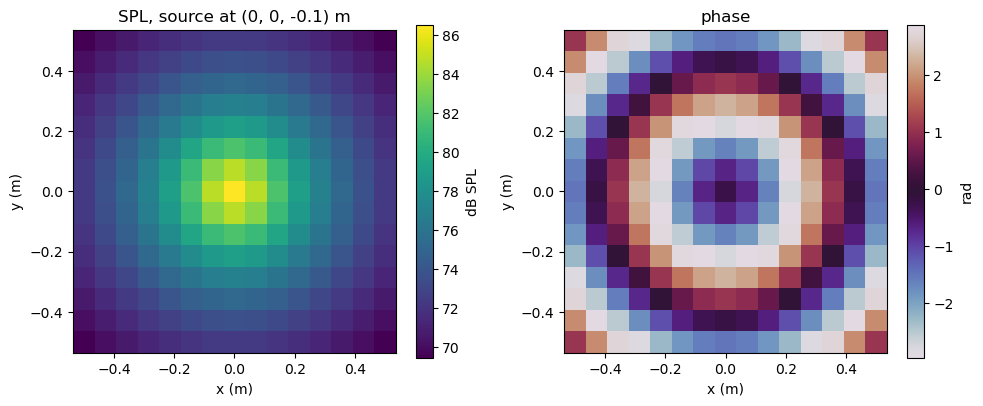

In [ ]:
def distance(X, Y, Z, r0):
    # Distance from point r0 = [x0, y0, z0] to points X, Y, Z.
    return np.sqrt((X - r0[0])**2 + (Y - r0[1])**2 + (Z - r0[2])**2)


def monopole(X, Y, Z, r0, f):
    # Complex pressure radiated by a monopole at r0 with volume velocity Q.
    k = 2 * np.pi * f / c
    R = distance(X, Y, Z, r0)
    return 1j * 2 * np.pi * f * rho * Q * np.exp(-1j * k * R) / (4 * np.pi * R)


r0 = [0.0, 0.0, -0.1]
p = monopole(X, Y, Z, r0, f)
SPL = 20 * np.log10(np.abs(p) / np.sqrt(2) / p_ref)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plot_map(axs[0], x, x, SPL, 'SPL, source at (0, 0, -0.1) m', 'dB SPL')
plot_map(axs[1], x, x, np.angle(p), 'phase', 'rad', cmap='twilight')
plt.tight_layout()
plt.show()

**ex1.B**:

Compute the wavenumber transform of this sound field and plot its magnitude. Analyze what happens if the
source radiates at a frequency of 500 Hz, instead of 1 kHz.

- Complete the `wavenumber_transform` function: zero-pad to $N\times N$, evaluate Eq. (2) with an FFT and centre the spectrum using `np.fft.fftshift`. You can scale by $\Delta x\,\Delta y N^2$ so that the sum approximates the integral.
- Complete `wavenumber_axis` to get the wavenumbers of the calculated (centred) spectrum.

Questions: Where is the energy concentrated, and why? Why is part of the spectrum outside the radiation circle? What changes at 500 Hz?

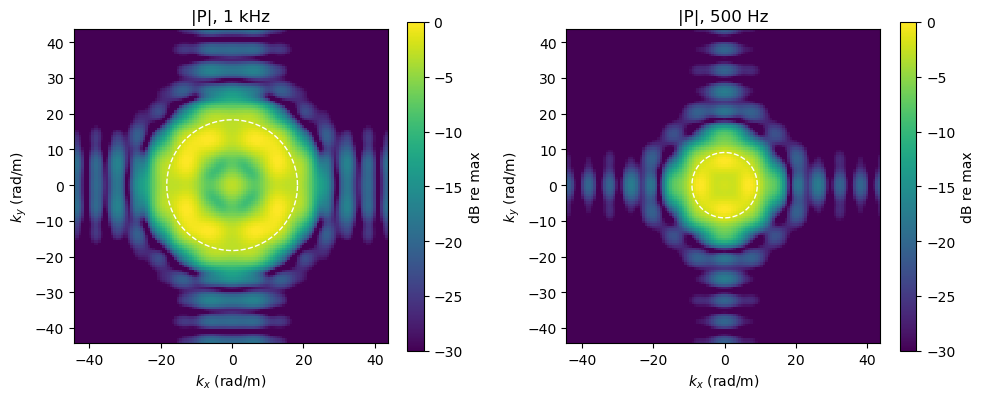

In [ ]:
def wavenumber_transform(p, dx, dy, N):
    # Eq. (2) for p[iy, ix] sampled with spacing dx, dy, zero padded to N x N and centred.
    P = dx * dy * N**2 * np.fft.ifft2(p, s=(N, N)) 
    return np.fft.fftshift(P)


def wavenumber_axis(N, dx):
    # Wavenumbers of the centred N-point spectrum for spacing dx.
    return 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, dx))


kx = wavenumber_axis(N, dx)
ky = wavenumber_axis(N, dx)
P = wavenumber_transform(p, dx, dx, N)
P500 = wavenumber_transform(monopole(X, Y, Z, r0, 500.0), dx, dx, N)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plot_kspace(axs[0], kx, ky, P, 2 * np.pi * f / c, '|P|, 1 kHz')
plot_kspace(axs[1], kx, ky, P500, 2 * np.pi * 500 / c, '|P|, 500 Hz')
plt.tight_layout()
plt.show()

*Observations.* At 1 kHz the spectrum fills the radiation circle ($k=18.3$ rad/m) and has a maximum just inside the ring $k_x^2+k_y^2=k$. The spherical wave radiated by the monople requires plane waves all around. Outside the circle the level decays as $e^{-\sqrt{k_x^2+k_y^2-k^2}\,d}$. These are evanescent waves, still measurable because $d=0.1$ m is only $\lambda/3.4$. At 500 Hz the radiation circle shrinks to $k=9.2$ rad/m.

**ex1.B-bonus(a)**: From the wavenumber spectrum you obtained, what would you observe if you calculate back the pressure at $z=0$, this time, over a larger aperture.

*Observations.* On the microphone positions the inverse transform returns the measured pressure since the wavenumber transform is just a change of basis. Over a larger aperture, however, it does not extrapolate the field of the monopole. It returns the measured $1\times1 \text{m}^2$ patch surrounded by zeros (because of the zero padding), repeated every $N\Delta x$ in $x$ and $y$. The DFT samples the spectrum at $\Delta k=2\pi/(N\Delta x)$, and sampling in $k$ implies periodicity in space. In NAH these replicas become important as soon as the spectrum is propagated with Eq. (4). The field of each replica spreads and wraps around into the aperture of interest. The goal of zero padding is to keeps the replicas far apart.

**ex1.B-bonus(b)**: You probably have observed cross-shaped ripples along the axes in the spectrum plots. Can you explain where the ripples come from? Can you think of a way to mitigate them?

*Observations.* The ripples are leakage from truncating the field at the edges of the aperture. Truncating the field is a multiplication by a rectangular window, so the spectrum is convolved with a 2D sinc. A window that tapers the pressure smoothly to zero at the edges removes the discontinuity, and the side lobes decay much faster.

**ex1.C**:

Place the monopole near a corner of the array at $(L/2,L/2,-0.1)$ m (again radiating at 1 kHz). Examine the pressure and its wavenumber spectrum.

Questions: In which quadrant of the $(k_x,k_y)$ plane is the energy, and why? How does windowing the field at the edges of the aperture affect the spectrum?

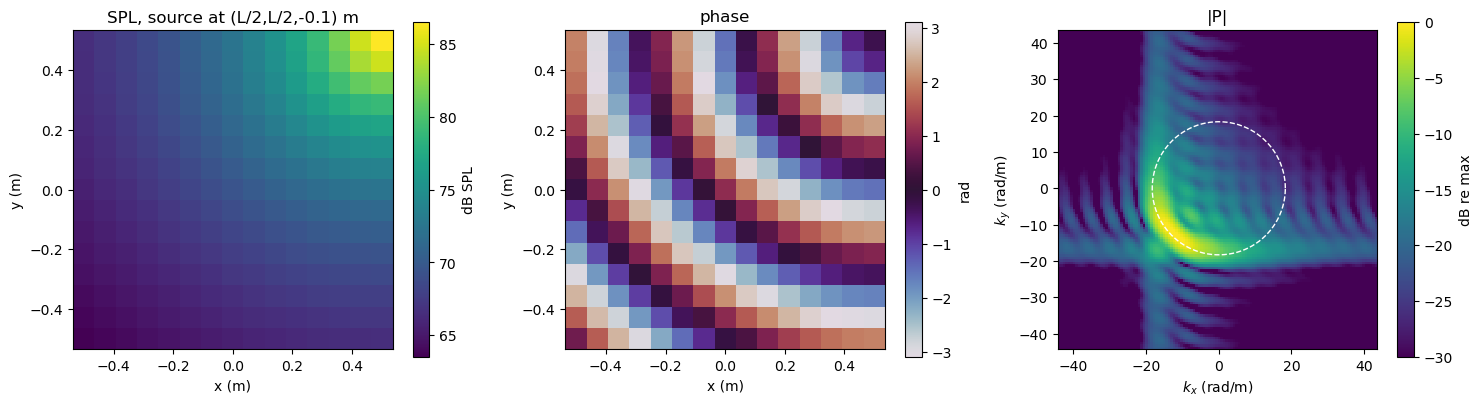

In [6]:
r0_corner = [L / 2, L / 2, -0.1]
pC = monopole(X, Y, Z, r0_corner, f)
PC = wavenumber_transform(pC, dx, dx, N)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
plot_map(axs[0], x, x, 20 * np.log10(np.abs(pC) / np.sqrt(2) / p_ref), 'SPL, source at (L/2,L/2,-0.1) m', 'dB SPL')
plot_map(axs[1], x, x, np.angle(pC), 'phase', 'rad', cmap='twilight')
plot_kspace(axs[2], kx, ky, PC, 2 * np.pi * f / c, '|P|')
plt.tight_layout()
plt.show()

*Observations.* Only a quarter of the radiated pressure falls within the aperture. The spectrum concentrates on the radiation circle in the quadrant $k_x<0$, $k_y<0$. The waves travel away from the corner, towards $-x$ and $-y$, and with $p\propto e^{-\mathrm{j}(k_xx+k_yy)}$ this means negative $k_x$ and $k_y$. The strong streaks parallel to the axes are leakage. The field is windowed at $x=L/2$ and $y=L/2$ where it is strongest, acting as a sharp window.

**ex1.D**:

Place the monopole 3 m away from the array, at $(0,0,-3)$ m. Examine the pressure and its wavenumber spectrum.

Questions: How much do the level and the phase vary over the array? Is there any evanescent content? What sets the width of the peak and the side lobes?

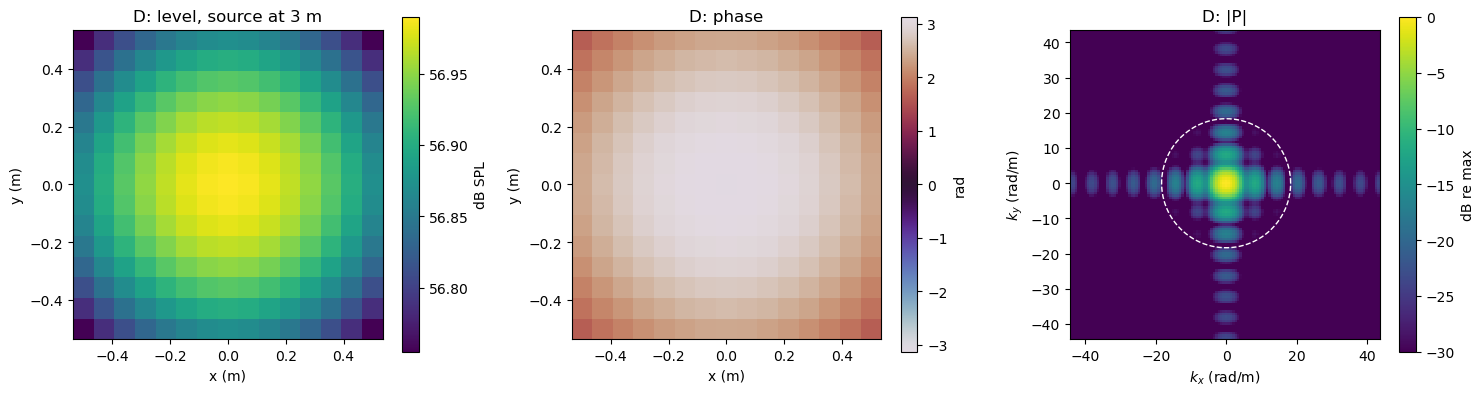

In [7]:
r0_far = [0.0, 0.0, -3.0]
pD = monopole(X, Y, Z, r0_far, f)
PD = wavenumber_transform(pD, dx, dx, N)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
plot_map(axs[0], x, x, 20 * np.log10(np.abs(pD) / np.sqrt(2) / p_ref), 'D: level, source at 3 m', 'dB SPL')
plot_map(axs[1], x, x, np.angle(pD), 'D: phase', 'rad', cmap='twilight')
plot_kspace(axs[2], kx, ky, PD, 2 * np.pi * f / c, 'D: |P|')
plt.tight_layout()
plt.show()

*Observations.* The level varies by only approx. 0.2 dB and the phase by 1.5 rad across the array. At 3 m the field is close to a plane wave at normal incidence, with a slightly curved wavefront. The spectrum has a maximum at $k_x=k_y=0$ with sinc-like side lobes along the axes. It is the transform of the aperture window. The main lobe extends to about $\pm2\pi/(M\Delta x)$, which sets the resolution. There is no evanescent content, since it has decayed. Far from the source the wavenumber spectrum shows the direction of arrival.

The wavenumber transform also allows as to compute the acoustic particle velocity field. Applying Euler's equation, $\mathbf{u}=-\frac{\nabla p}{\mathrm{j}\omega\rho_0}$, to Eq. (2) gives the normal velocity spectrum

$$U_z(k_x,k_y,z)=\frac{k_z}{\rho_0ck}\,P(k_x,k_y,z). \tag{5}$$

From there we can simply take the inverse wavenumber transform to get the velocity in the $z$ direction. One can see that for propagating waves $u_z$ is in phase with $p$ (scaled by a factor $\cos\theta/\rho_0c$). For evanescent waves $k_z$ is imaginary, thus $p$ and $u_z$ are in quadrature, and no active intensity flows along $z$.

**ex1.E**:

Compute the wavenumber spectrum of the normal particle velocity $u_z$ for the source at $(0,0,-0.1)$ m, at 1 kHz. For that you will need to compute $k_z$ first (`axial_wavenumber` function).

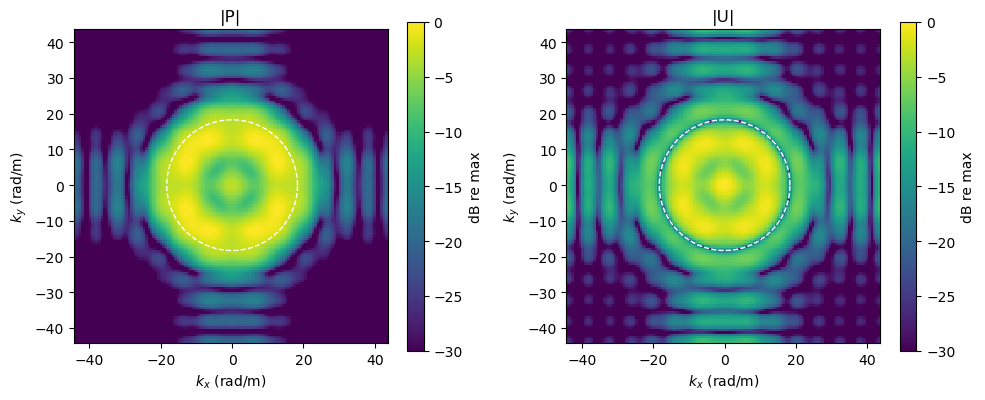

In [ ]:
def axial_wavenumber(KX, KY, k):
    # k_z: real and positive for propagating waves, negative imaginary for evanescent waves.
    return -1j * np.sqrt(KX**2 + KY**2 - k**2 + 0j)


k = 2 * np.pi * f / c
KX, KY = np.meshgrid(kx, ky)
kz = axial_wavenumber(KX, KY, k)
Uz = kz / (rho * c * k) * P

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plot_kspace(axs[0], kx, ky, P, k, '|P|')
plot_kspace(axs[1], kx, ky, Uz, k, '|U|')
plt.tight_layout()
plt.show()

**References**
- [Jacobsen2013] F. Jacobsen and P. M. Juhl, *Fundamentals of General Linear Acoustics*, Wiley, 2013 (Section 9.5).
- [Williams1999] E. G. Williams, *Fourier Acoustics: Sound Radiation and Nearfield Acoustical Holography*, Academic Press, 1999.
- [Maynard1985] J. D. Maynard, E. G. Williams and Y. Lee, "Nearfield acoustic holography: I. Theory of generalized holography and the development of NAH", *J. Acoust. Soc. Am.* 78(4), 1395–1413, 1985.